In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory
from ast import literal_eval
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/kse-ua-location-extraction-2026/ru_geo_dataset.csv
/kaggle/input/competitions/kse-ua-location-extraction-2026/README.md
/kaggle/input/competitions/kse-ua-location-extraction-2026/labeling_sample.csv
/kaggle/input/competitions/kse-ua-location-extraction-2026/test.csv
/kaggle/input/competitions/kse-ua-location-extraction-2026/uk_geo_dataset.csv
/kaggle/input/competitions/kse-ua-location-extraction-2026/uk_geo_dataset_processed_v1.parquet


# EDA

## UKRAINE

In [2]:
uk_geo =pd.read_csv("/kaggle/input/competitions/kse-ua-location-extraction-2026/uk_geo_dataset.csv", converters={'loc_markers': literal_eval, 'org_markers':literal_eval, 'per_markers':literal_eval})

In [3]:
test = pd.read_csv("/kaggle/input/competitions/kse-ua-location-extraction-2026/test.csv")

In [4]:
uk_geo

,text,loc_markers,org_markers,per_markers,is_valid
0,"Чим довше мають скачки тиску гіпертензією, тим...",[],[],[],0
1,"А поки що починали цвісти троянди, випускники ...",[],[],"[(114, 131)]",0
2,"Крім того, в 2020 р. багато експертів прогнозу...",[],[],[],0
3,"Сильно сумніваюся, що ви зупините свій вибір н...",[],[],[],0
4,Цей унікальний правовий важіль утворено 1998 р...,[],[],[],0
...,...,...,...,...,...
1009995,"Траєкторія польоту цих літаків є провокуючою”,...",[],[],"[(56, 63)]",1
1009996,Якщо порівняти у відсотковому співвідношенні к...,[],[],[],1
1009997,"У інфікувалися четверо жінок, наймолодшій із н...",[],[],[],1
1009998,"Хочу запевнити, що створення Православної Церк...",[],"[(29, 56)]",[],1


In [5]:
print(sum(uk_geo["text"].isna().astype(int)))
print(sum(uk_geo["loc_markers"].isna().astype(int)))
print(sum(uk_geo["org_markers"].isna().astype(int)))
print(sum(uk_geo["per_markers"].isna().astype(int)))

0
0
0
0


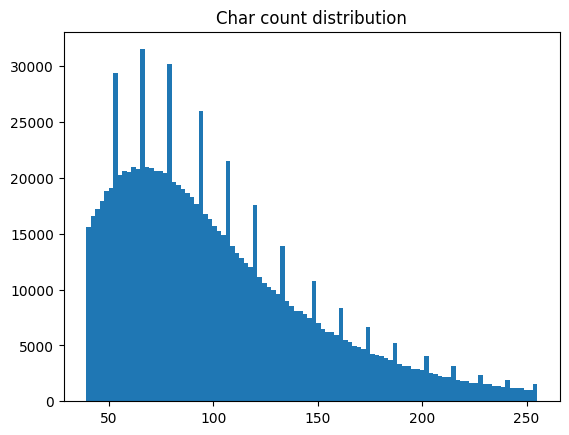

In [11]:
counts = uk_geo["text"]
counts = counts.apply(lambda x: len(x))
plt.hist(counts, bins =100)
plt.title("Char count distribution")
plt.show()


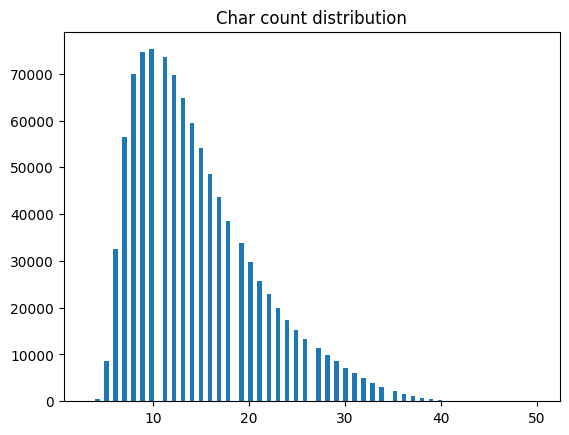

In [12]:
counts = uk_geo["text"]
counts = counts.apply(lambda x: len(x.strip().split()))
plt.hist(counts, bins =100)
plt.title("Char count distribution")
plt.show()


In [13]:
import re
from collections import Counter
import matplotlib.pyplot as plt

def plot_top_words(series, top_n=50, stopwords=None, min_len=2, lowercase=True):
    """Count word frequencies in a text Series and plot the top_n words."""
    stopwords = set(stopwords or [])
    counter = Counter()

    for text in series.dropna().astype(str):
        if lowercase:
            text = text.lower()
        # \w+ handles Unicode, so Ukrainian/Russian/English words all work
        words = re.findall(r"\w+", text)
        counter.update(w for w in words if len(w) >= min_len and w not in stopwords)

    top = counter.most_common(top_n)
    words, counts = zip(*top)

    fig, ax = plt.subplots(figsize=(10, top_n * 0.25 + 1))
    ax.barh(words[::-1], counts[::-1], color="steelblue")
    ax.set_title(f"Top {top_n} most frequent words")
    ax.set_xlabel("Count")
    plt.tight_layout()
    plt.show()

    return top  # list of (word, count), handy for further inspection

## russia

In [14]:
ru_geo= pd.read_csv("/kaggle/input/competitions/kse-ua-location-extraction-2026/ru_geo_dataset.csv", converters={'loc_markers': literal_eval, 'org_markers':literal_eval, 'per_markers':literal_eval})

In [15]:
ru_geo

,text,loc_markers,org_markers,per_markers,doc_id,sent_id
0,Вице-премьер по социальным вопросам Татьяна Го...,"[(82, 88)]","[(149, 160)]","[(36, 52)]",0,0
1,"По словам Голиковой, чаще всего онкологические...","[(89, 98), (100, 108), (110, 118), (121, 139),...",[],"[(10, 19)]",0,1
2,"Вице-премьер напомнила, что главные факторы см...","[(57, 63)]",[],[],0,2
3,"В начале года стало известно, что смертность о...",[],[],[],0,3
4,"По данным Росстата, в 2017 году от рака умерли...",[],"[(10, 18)]",[],0,4
...,...,...,...,...,...,...
8028835,Общественный штаб поддержки победившего на выб...,"[(150, 168)]",[],"[(51, 69)]",739344,16
8028836,"По данным штаба, минувшим днем при возвращении...",[],[],"[(163, 179), (279, 294)]",739344,17
8028837,"Штаб поддержки Владимира Семенова отмечает, чт...","[(95, 113)]","[(203, 209)]","[(15, 33)]",739344,18
8028838,На состоявшейся сегодня в Москве пресс-конфере...,"[(26, 32), (93, 95)]","[(62, 81), (156, 170)]","[(96, 114), (200, 214)]",739345,0


In [16]:
locations_ru = np.zeros((2000,2000))
for  i in ru_geo["loc_markers"]:
    if len(i) != 0:
        for j in i:
            locations_ru[*j] =locations_ru[*j] + 1
orgs_ru = np.zeros((2000,2000))
for  i in ru_geo["org_markers"]:
    if len(i) != 0:
        for j in i:
            orgs_ru[*j] =orgs_ru[*j] + 1
pers_ru = np.zeros((2000,2000))
for  i in ru_geo["per_markers"]:
    if len(i) != 0:
        for j in i:
            pers_ru[*j] =pers_ru[*j] + 1    

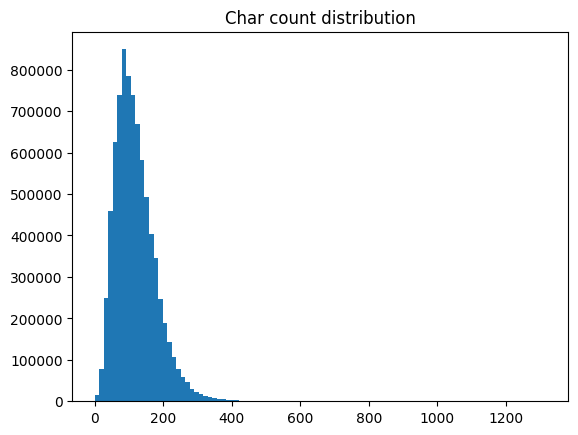

In [20]:
counts = ru_geo["text"]
counts = counts.apply(lambda x: len(x))
plt.hist(counts,bins = 100)
plt.title("Char count distribution")
plt.show()

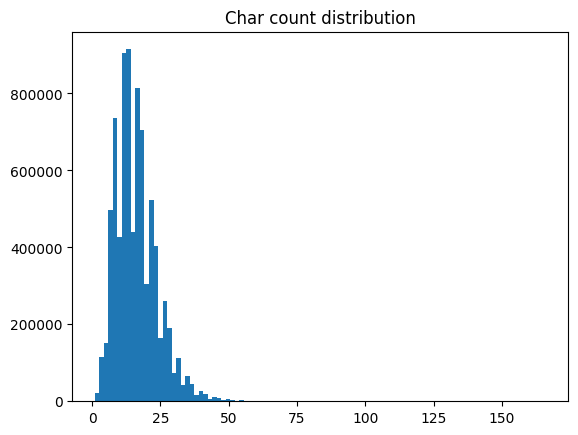

In [21]:
counts = ru_geo["text"]
counts = counts.apply(lambda x: len(x.strip().split()))
plt.hist(counts,bins = 100)
plt.title("Char count distribution")
plt.show()

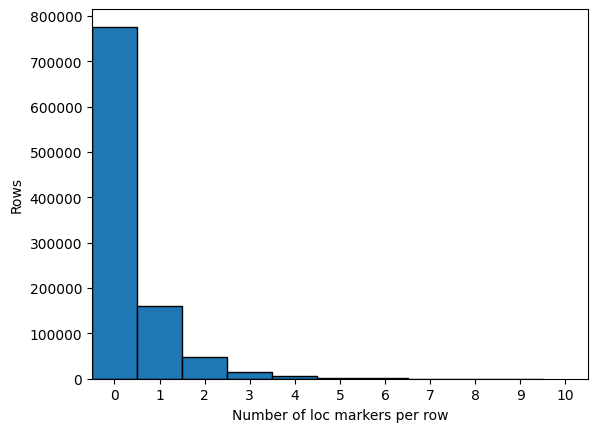

In [22]:
loc_counts = uk_geo["loc_markers"].apply(len)
plt.hist(loc_counts, bins=np.arange(0, 11) - 0.5, edgecolor="black")  # bins centered on integers 0..10
plt.xlim(-0.5, 10.5)
plt.xticks(range(0, 11))
plt.xlabel("Number of loc markers per row")
plt.ylabel("Rows")
plt.show()

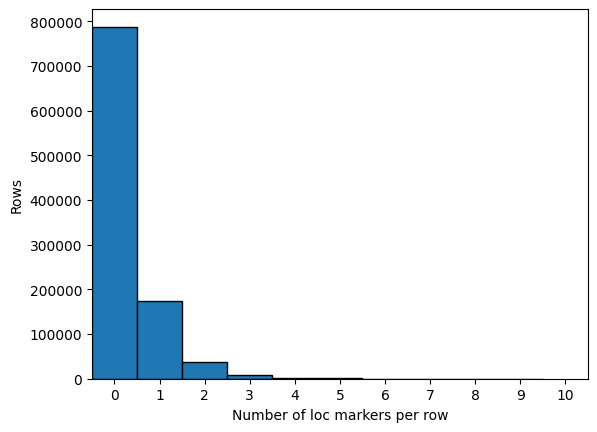

In [23]:
loc_counts = uk_geo["per_markers"].apply(len)
plt.hist(loc_counts, bins=np.arange(0, 11) - 0.5, edgecolor="black")  # bins centered on integers 0..10
plt.xlim(-0.5, 10.5)
plt.xticks(range(0, 11))
plt.xlabel("Number of loc markers per row")
plt.ylabel("Rows")
plt.show()

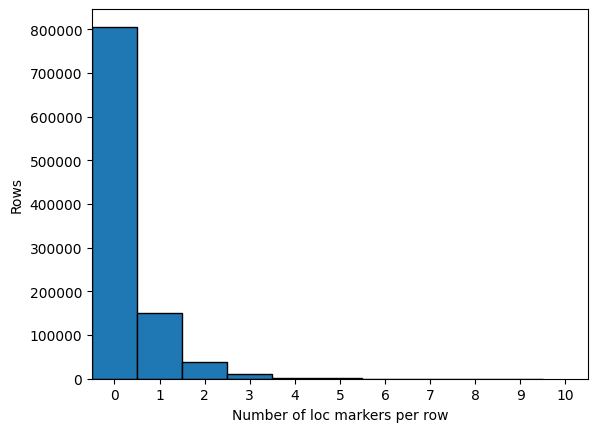

In [24]:
loc_counts = uk_geo["org_markers"].apply(len)
plt.hist(loc_counts, bins=np.arange(0, 11) - 0.5, edgecolor="black")  # bins centered on integers 0..10
plt.xlim(-0.5, 10.5)
plt.xticks(range(0, 11))
plt.xlabel("Number of loc markers per row")
plt.ylabel("Rows")
plt.show()

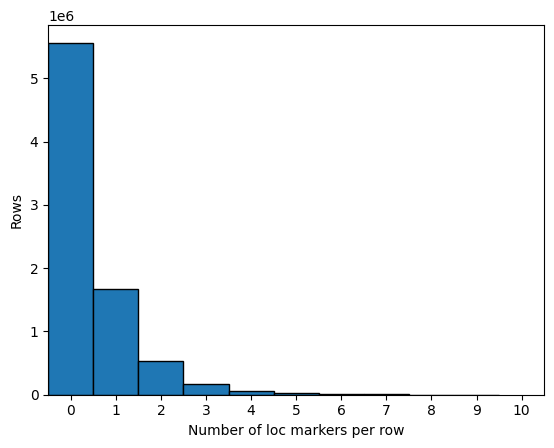

In [25]:
loc_counts = ru_geo["loc_markers"].apply(len)
plt.hist(loc_counts, bins=np.arange(0, 11) - 0.5, edgecolor="black")  # bins centered on integers 0..10
plt.xlim(-0.5, 10.5)
plt.xticks(range(0, 11))
plt.xlabel("Number of loc markers per row")
plt.ylabel("Rows")
plt.show()

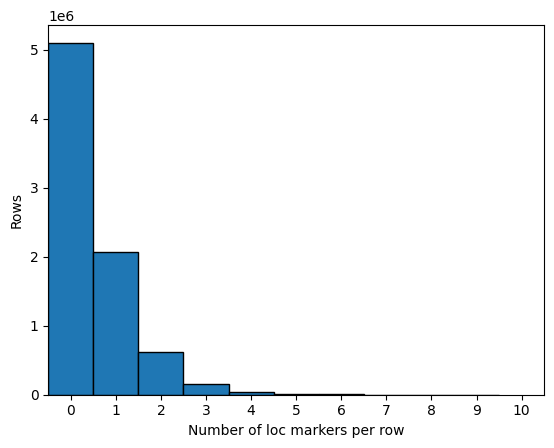

In [26]:
loc_counts = ru_geo["org_markers"].apply(len)
plt.hist(loc_counts, bins=np.arange(0, 11) - 0.5, edgecolor="black")  # bins centered on integers 0..10
plt.xlim(-0.5, 10.5)
plt.xticks(range(0, 11))
plt.xlabel("Number of loc markers per row")
plt.ylabel("Rows")
plt.show()

In [27]:
print(sum(ru_geo["text"].isna().astype(int)))
print(sum(ru_geo["loc_markers"].isna().astype(int)))
print(sum(ru_geo["org_markers"].isna().astype(int)))
print(sum(ru_geo["per_markers"].isna().astype(int)))

0
0
0
0


In [48]:
sum(uk_geo["is_valid"])

10000

# Key takeaways
- Data is valid!no imputing needed.
- Clear class imbalance, as the most data isconsisted of unclassified samples on each of columns in ru_geo and ukr_geo
- The median count of word is 50~100 on both uk_geo and ru_geo
- Ru geo, when validated, should be grouped by document_id to avoid data leakage
- i didn't understand what the hell is is_valid column and why would we need it i don't really know it's story so i cannot sufggest if there is a possible data leakage we can avoid or not.
- we may drop per_markers, and org markers butisuggestto keep themas a generalization method.


In [29]:
from tokenizers import ByteLevelBPETokenizer

tokenizer = ByteLevelBPETokenizer(
    add_prefix_space=False, 
    lowercase=True,       
    dropout=None,            
    unicode_normalizer="nfc"
    continuing_subword_prefix=None,
    end_of_word_suffix=None,
    trim_offsets=False,       
)   

In [30]:
merger =pd.concat([uk_geo["text"], ru_geo["text"]])

In [ ]:
merger

In [31]:
texts = merger.dropna().astype(str).tolist()
total_chars = sum(len(t) for t in texts)
total_tokens = total_chars / 4  # rough: ~4 chars per English token

print(f"Corpus size: ~{total_tokens:,} tokens")
print(f"Max practical vocab: {total_tokens // 10:,}")

Corpus size: ~265,318,501.25 tokens
Max practical vocab: 26,531,850.0


In [32]:
tokenizer.train_from_iterator(merger.tolist(), vocab_size=50257, min_frequency=2,
                special_tokens=["", "<pad>", "", "<unk>", "<mask>"])   

In [33]:
tokenizer

Tokenizer(vocabulary_size=50257, model=ByteLevelBPE, add_prefix_space=False, lowercase=True, dropout=None, unicode_normalizer=nfc, continuing_subword_prefix=None, end_of_word_suffix=None, trim_offsets=False)

In [43]:
# Single text
encoding = tokenizer.encode("Я люблю україну")
print(encoding.ids)       # list of token IDs
print(encoding.tokens)    # list of byte-level token strings
print(tokenizer.decode(encoding.ids))  # back to text

# Batch: entire DataFrame column
ids = [tokenizer.encode(t).ids for t in uk_geo["text"].dropna().astype(str)]

# Or use the faster batched encode:
encodings = tokenizer.encode_batch(uk_geo["text"].dropna().astype(str).tolist())
ids = [enc.ids for enc in encodings]   

[1009, 7182, 82, 8467]
['he', 'll', 'o', 'Ġworld']
hello world


In [44]:
encoding = tokenizer.encode("Я тебе говорю, шкет, археомодерн имманентен консервативному дискурсу»: Дугин довёл до слёз второклассника на открытом уроке «Русский логос»")
print(encoding.ids)       # list of token IDs
print(encoding.tokens)    # list of byte-level token strings
print(tokenizer.decode(encoding.ids))  # back to text

[274, 17990, 32497, 15, 3640, 301, 15, 11472, 297, 298, 1722, 967, 1370, 362, 283, 16864, 984, 3777, 447, 1630, 20485, 22678, 323, 2298, 8348, 270, 529, 454, 8348, 288, 998, 20648, 913, 311, 13780, 15350, 263, 449, 15608, 7220, 327, 414]
['Ñı', 'ĠÑĤÐµÐ±Ðµ', 'ĠÐ³Ð¾Ð²Ð¾ÑĢÑİ', ',', 'ĠÑĪÐº', 'ÐµÑĤ', ',', 'ĠÐ°ÑĢÑħÐµ', 'Ð¾Ð¼', 'Ð¾Ð´', 'ÐµÑĢÐ½', 'ĠÐ¸Ð¼', 'Ð¼Ð°Ð½', 'ÐµÐ½ÑĤ', 'ÐµÐ½', 'ĠÐºÐ¾Ð½ÑģÐµÑĢÐ²Ð°ÑĤÐ¸Ð²', 'Ð½Ð¾Ð¼Ñĥ', 'ĠÐ´Ð¸ÑģÐº', 'ÑĥÑĢ', 'ÑģÑĥ', 'Â»:', 'ĠÐ´ÑĥÐ³', 'Ð¸Ð½', 'ĠÐ´Ð¾Ð²', 'Ñĳ', 'Ð»', 'ĠÐ´Ð¾', 'ĠÑģÐ»', 'Ñĳ', 'Ð·', 'ĠÐ²ÑĤÐ¾ÑĢ', 'Ð¾ÐºÐ»Ð°ÑģÑģ', 'Ð½Ð¸ÐºÐ°', 'ĠÐ½Ð°', 'ĠÐ¾ÑĤÐºÑĢÑĭÑĤÐ¾Ð¼', 'ĠÑĥÑĢÐ¾Ðº', 'Ðµ', 'ĠÂ«', 'ÑĢÑĥÑģÑģÐºÐ¸Ð¹', 'ĠÐ»Ð¾Ð³', 'Ð¾Ñģ', 'Â»']
я тебе говорю, шкет, археомодерн имманентен консервативному дискурсу»: дугин довёл до слёз второклассника на открытом уроке «русский логос»


In [46]:
tokenizer.save("rua_bpe_tokenizer.json")   

In [52]:
pd.read_csv("/kaggle/input/competitions/kse-ua-location-extraction-2026/labeling_sample.csv")

,text,locations,loc_markers
0,-261.310,[],[]
1,"Проспект Бандери стоїть, як і пів міста… довго...",['Проспект Бандери'],"[(0, 16)]"
2,☢️Радіаційний фон (мкР/год) по Київщині станом...,"['Київщині', 'Чорнобиль', 'Київ', 'Тетерів', '...","[(31, 39), (68, 77), (83, 87), (93, 100), (105..."
3,"Друзі. Останні дві ночі, і ще декілька наступн...",['проспекті Івасюка'],"[(134, 151)]"
4,Сьогодні з Києва до Хелма вперше вирушив новий...,"['Києва', 'Хелма']","[(11, 16), (20, 25)]"
5,Подовження роботи закладів харчування\n\nВладо...,['Києву'],"[(861, 866)]"
6,"Нарешті офіційні новини, які можна розповідати...",[],[]
7,ДТП біля заїзду в ТЦ Аркадія\n\n📍Індустріальни...,['ТЦ Аркадія'],"[(18, 28)]"
8,“Київський метрополітен” отримав ще 6 вагонів ...,[],[]
9,В результате массированной атаки врага ночью в...,"['Фастовском', 'Бучанском']","[(47, 57), (60, 69)]"


In [53]:
pd.read_parquet("/kaggle/input/competitions/kse-ua-location-extraction-2026/uk_geo_dataset_processed_v1.parquet")

,tokens,labels,is_valid
0,"[""\u0427\u0438\u043c"",""\u0434\u043e\u0432\u044...","[""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""...",0
1,"[""\u0410"",""\u043f\u043e\u043a\u0438"",""\u0449\u...","[""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""...",0
2,"[""\u041a\u0440\u0456\u043c"",""\u0442\u043e\u043...","[""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""...",0
3,"[""\u0421\u0438\u043b\u044c\u043d\u043e"",""\u044...","[""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O""]",0
4,"[""\u0426\u0435\u0439"",""\u0443\u043d\u0456\u043...","[""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O""]",0
...,...,...,...
1009995,"[""\u0422\u0440\u0430\u0454\u043a\u0442\u043e\u...","[""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O""]",1
1009996,"[""\u042f\u043a\u0449\u043e"",""\u043f\u043e\u044...","[""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""...",1
1009997,"[""\u0423"",""\u0456\u043d\u0444\u0456\u043a\u044...","[""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""...",1
1009998,"[""\u0425\u043e\u0447\u0443"",""\u0437\u0430\u043...","[""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""O"",""...",1


In [62]:
# B - beginning token that containssomething important ,I- inner token, O -outside token
# 7 classes: O + BIO for LOC / ORG / PER
LABEL2ID = {"O": 0, "B-LOC": 1, "I-LOC": 2, "B-ORG": 3, "I-ORG": 4, "B-PER": 5, "I-PER": 6}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}

# entity type id t -> B label = 2*t - 1, I label = 2*t
# applied in this order, so on overlap the later one wins (LOC has priority)
ENTITY_COLS = [("per_markers", 3), ("org_markers", 2), ("loc_markers", 1)]


def parse_spans(x):
    """Handles strings like '[(82, 88)]', lists, numpy arrays, None/NaN."""
    if x is None or (isinstance(x, float) and np.isnan(x)):
        return []
    if isinstance(x, str):
        x = ast.literal_eval(x)
    return [(int(a), int(b)) for a, b in x]


def char_arrays(n, spans_by_type):
    """Per-character entity type + 'this char starts an entity' flag."""
    ctype = np.zeros(n, dtype=np.int8)
    cstart = np.zeros(n, dtype=bool)
    for t, spans in spans_by_type:
        for a, b in spans:
            a, b = max(a, 0), min(b, n)
            if b > a:
                ctype[a:b] = t
                cstart[a:b] = False   # clear starts of anything we overwrite
                cstart[a] = True
    return ctype, cstart


def tokens_to_labels(offsets, ctype, cstart):
    labels = []
    for s, e in offsets:
        if e <= s:                       # special tokens have (0, 0)
            labels.append(-100)
            continue
        seg_t = ctype[s:e]
        nz = np.flatnonzero(seg_t)
        if len(nz) == 0:
            labels.append(0)
            continue
        t = int(seg_t[nz[0]])
        is_b = cstart[s:e].any()         # token contains the first char of the entity
        labels.append(2 * t - 1 if is_b else 2 * t)
    return labels


def process_dataset(df, tokenizer, text_col="text", max_len=256, batch_size=10_000):
    tokenizer.enable_truncation(max_length=max_len)
    cols = {c: df[c].tolist() for c, _ in ENTITY_COLS}
    texts = df[text_col].astype(str).tolist()

    all_ids, all_labels = [], []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i + batch_size]
        encs = tokenizer.encode_batch(batch)
        for k, (text, enc) in enumerate(zip(batch, encs), start=i):
            spans_by_type = [(t, parse_spans(cols[c][k])) for c, t in ENTITY_COLS]
            ctype, cstart = char_arrays(len(text), spans_by_type)
            all_ids.append(enc.ids)
            all_labels.append(tokens_to_labels(enc.offsets, ctype, cstart))

    out = pd.DataFrame({"input_ids": all_ids, "labels": all_labels})
    if "is_valid" in df.columns:
        out["is_valid"] = df["is_valid"].values
    return out

In [63]:
merge_uk_geo = uk_geo[["text", "loc_markers", "org_markers", "per_markers"]].copy()
merge_ru_geo = ru_geo[["text", "loc_markers", "org_markers", "per_markers", "doc_id"]].copy()

# Use max(), not iloc[-1]: the last row isn't guaranteed to hold the largest id
start_id = int(merge_ru_geo["doc_id"].max()) + 1

# One unique id per uk row
merge_uk_geo["doc_id"] = np.arange(start_id, start_id + len(merge_uk_geo))

merged = pd.concat([merge_ru_geo, merge_uk_geo], ignore_index=True)

In [ ]:
output = process_dataset(merged,tokenizer,)